# 03 — Renovação

**Pergunta de negócio.** Na renovação de cada grupo, quanto reajustar a taxa, e quanto confiar na
experiência do próprio grupo em vez da taxa manual?

**Fluxo, para cada grupo na data de avaliação:**
1. **Pooling.** Nível de pooling = max(piso, 3 × capital médio das vidas ativas), limitado à retenção.
   Sinistros acima do nível saem da experiência do grupo; o excesso esperado vira encargo de pooling,
   cobrado de todos.
2. **Experiência contra a taxa manual**, não contra a tábua: A/E = (sinistros limitados avisados + IBNR)
   / esperado limitado pela manual. A credibilidade mistura experiência e manual, então o A/E tem de ser
   medido em relação à manual.
3. **IBNR:** padrão de aviso da carteira por chain ladder mensal (pacote chainladder) e alocação por grupo
   no estilo Bornhuetter-Ferguson (esperados × fração ainda não avisada).
4. **Credibilidade Z**, por dois métodos:
   - **mercado:** flutuação limitada (regra da raiz) em vidas-ano, com a ordem de grandeza usada em vida em
     grupo (plena perto de 20 mil vidas-ano, mínima de 500);
   - **Bühlmann-Straub:** k estimado nos dados (variância dentro ÷ variância entre grupos), com peso igual ao
     número efetivo de óbitos (que penaliza concentração de capital). Conferido com `actuar::cm` no R.
5. **Reajuste:** taxa de renovação = [custo limitado na manual sobre o censo atual × (Z·A/E + 1 − Z) +
   encargo de pooling] ÷ capital; comercial = pura ÷ (1 − carregamento); reajuste sobre a taxa vigente, com
   piso e teto. Compara-se com a regra contratual por faixa de sinistralidade (75%/85%).

Parâmetros em `config/renovacao.yaml` (carregamento, piso, teto e retenção são ilustrativos).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, renovacao as R, backtest as B, verdade as V
from vgpricing.glmm import r_disponivel
from vgpricing.exposicao import exposicao_detalhada

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cr, cs = (carregar_config(n, RAIZ) for n in ("base", "manual", "renovacao", "sintetico"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"
pasta = RAIZ / "data/synthetic"
dados = {t: pd.read_parquet(pasta / "limpo" / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros", "premios")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")      # gerada no notebook 02
REF = pd.Timestamp(cfg["data_referencia"])
print("Taxa manual:", tabela["meta"]["formula"], "| corte:", tabela["meta"]["corte_experiencia"])

Taxa manual: N ~ log_capital_c + cnae_secao + (1 | cnae_secao:cnae_divisao) + (1 | id_estipulante) + offset(log(E)) | corte: 2024-12-31


## 1. Renovação da carteira na data de referência

In [2]:
ren = R.renovar_carteira(dados, tabua, tabela, cr, REF)
P = ren["pooling"]
print(f"A/E a priori da carteira contra a manual (contagem, valor limitado): {ren['ae_apriori'][0]:.3f}, {ren['ae_apriori'][1]:.3f}")
pd.Series({"grupos": len(P), "nível de pooling mediano (R$)": P.median(), "grupos no teto de retenção": int((P >= cr['pooling']['limite_retencao']).sum())}).to_frame("valor")

A/E a priori da carteira contra a manual (contagem, valor limitado): 1.001, 0.981


,valor
grupos,250.0000
nível de pooling mediano (R$),"185,526.9770"
grupos no teto de retenção,0.0000


### 1.1 Pooling

In [3]:
xp = ren["experiencia"]
tot = xp[["V_manual", "V_excesso"]].sum()
print(f"Parcela do custo esperado acima do pooling (encargo): {tot['V_excesso'] / tot.sum():.1%}")
pd.Series({"sinistros avisados (R$)": xp["V_total"].sum(), "limitados ao pooling (R$)": xp["V"].sum(),
           "parcela que saiu da experiência dos grupos": 1 - xp["V"].sum() / xp["V_total"].sum()}).to_frame("valor")

Parcela do custo esperado acima do pooling (encargo): 3.1%


,valor
sinistros avisados (R$),"150,554,300.0000"
limitados ao pooling (R$),"144,943,038.6115"
parcela que saiu da experiência dos grupos,0.0373


O excesso sai da experiência do grupo (um sinistro de capital alto não "contamina" a renovação daquele
grupo) e volta como encargo para todos, na medida do capital acima do pooling de cada um.

### 1.2 IBNR

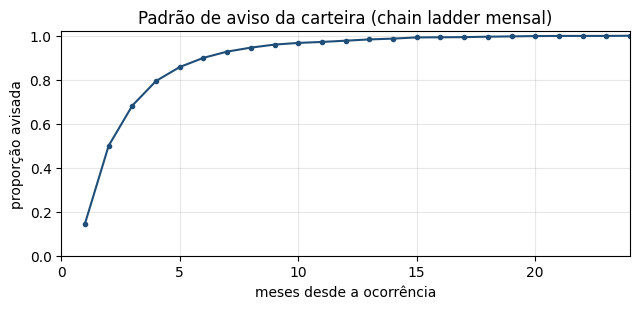

,idade_meses,ldf,cdf,proporcao_avisada
0,1,3.4231,6.8435,0.1461
1,2,1.3650,1.9992,0.5002
2,3,1.1635,1.4647,0.6828
3,4,1.0799,1.2589,0.7944
4,5,1.0487,1.1658,0.8578
5,6,1.0315,1.1117,0.8995


In [4]:
pn = ren["padrao_contagem"]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(pn["idade_meses"], pn["proporcao_avisada"], marker="o", ms=3, color="#1f4e79")
ax.set_xlim(0, 24); ax.set_ylim(0, 1.02); ax.set_xlabel("meses desde a ocorrência"); ax.set_ylabel("proporção avisada")
ax.set_title("Padrão de aviso da carteira (chain ladder mensal)"); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
pn.head(6)

In [5]:
ib = xp.assign(ano_ocorrencia=xp["inicio_ano"].dt.year).groupby("ano_ocorrencia")[["N", "IBNR_n"]].sum()
verd_ibnr = pd.read_parquet(pasta / "verdade_ibnr.parquet")                      # só no sintético
ib["IBNR verdadeiro (teste de software)"] = verd_ibnr.groupby(verd_ibnr["data_ocorrencia"].dt.year).size()
ib = ib.fillna(0)
ib.loc["total"] = ib.sum()
ib.tail(5)

,N,IBNR_n,IBNR verdadeiro (teste de software)
ano_ocorrencia,,,
2022,454.0000,0.0000,0.0000
2023,484.0000,0.4720,1.0000
2024,540.0000,18.5263,7.0000
2025,217.0000,94.0726,107.0000
total,"2,157.0000",113.0710,115.0000


O IBNR verdadeiro fica agrupado pelo ano de ocorrência, e o estimado pelo ano de início do ano-apólice;
por isso a comparação é aproximada ano a ano, mas os totais devem ficar próximos. A regra contratual usa
15% do prêmio como IBNR, independentemente da idade da experiência.

### 1.3 Credibilidade

In [6]:
bs = ren["bs"]
saida = pd.Series({"variância dentro (s²)": bs["s2"], "variância entre grupos (a)": bs["a"], "k = s²/a (em óbitos efetivos)": bs["k"],
                   "média da carteira (A/E)": bs["media_carteira"], "grupos": bs["grupos"]})
if r_disponivel():
    from vgpricing.r_credibilidade import buhlmann_straub_actuar
    rr = buhlmann_straub_actuar(xp.dropna(subset=["AE_v"]), "id_estipulante", "ano_apolice", "AE_v", "n_ef")
    saida["k pelo actuar::cm (conferência)"] = rr["k"]
saida.to_frame("Bühlmann-Straub")

,Bühlmann-Straub
variância dentro (s²),1.0319
variância entre grupos (a),0.0551
k = s²/a (em óbitos efetivos),18.7120
média da carteira (A/E),1.0220
grupos,250.0000
k pelo actuar::cm (conferência),18.7120


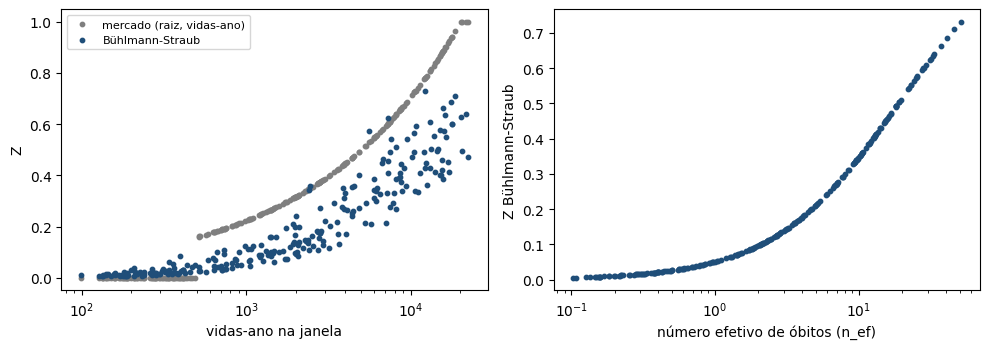

In [7]:
f = ren["fatores"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(f["vidas_ano"], f["Z_mercado"], s=10, label="mercado (raiz, vidas-ano)", color="#7f7f7f")
ax[0].scatter(f["vidas_ano"], f["Z_bs"], s=10, label="Bühlmann-Straub", color="#1f4e79")
ax[0].set_xscale("log"); ax[0].set_xlabel("vidas-ano na janela"); ax[0].set_ylabel("Z"); ax[0].legend(fontsize=8)
ax[1].scatter(f["n_ef"], f["Z_bs"], s=10, color="#1f4e79"); ax[1].set_xscale("log")
ax[1].set_xlabel("número efetivo de óbitos (n_ef)"); ax[1].set_ylabel("Z Bühlmann-Straub")
plt.tight_layout(); plt.show()

À esquerda: para o mesmo número de vidas-ano, o Bühlmann-Straub dá credibilidades diferentes conforme a
concentração de capital (grupos com poucas vidas de capital alto recebem menos). A regra de mercado só olha
vidas-ano. À direita: no Bühlmann-Straub, Z depende só de n_ef, por construção.

Note também que, com os limiares de mercado (plena em 20 mil vidas-ano), a regra da raiz dá **mais**
credibilidade que a estimada pelos dados. No levantamento da SOA com seguradoras de grupo, uma delas
relatou o mesmo ao testar a própria fórmula com dados históricos: ela dava credibilidade demais,
principalmente a grupos com pouco volume de sinistros.

### 1.4 Reajuste técnico × regra contratual

In [8]:
rj = ren["reajustes"]
pd.DataFrame({"reajuste técnico (aplicado)": rj["reajuste_aplicado"].describe(),
              "regra contratual": rj["reajuste_regra"].describe()})

,reajuste técnico (aplicado),regra contratual
count,250.0000,250.0000
mean,-0.0494,0.0422
std,0.1279,0.0664
min,-0.1500,0.0000
25%,-0.1500,0.0000
50%,-0.1024,0.0000
75%,0.0255,0.1500
max,0.4000,0.1500


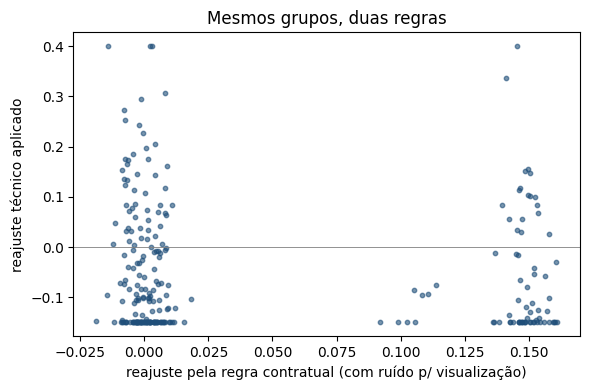

reajuste_regra,0.0000,0.1000,0.1500,All
reajuste_aplicado,,,,
redução,108,8,42,158
estável,31,0,8,39
até 20%,28,0,13,41
acima de 20%,10,0,2,12
All,177,8,65,250


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(rj["reajuste_regra"] + np.random.default_rng(0).normal(0, 0.006, len(rj)), rj["reajuste_aplicado"], s=10, alpha=0.6, color="#1f4e79")
ax.axhline(0, color="grey", lw=0.6); ax.set_xlabel("reajuste pela regra contratual (com ruído p/ visualização)")
ax.set_ylabel("reajuste técnico aplicado"); ax.set_title("Mesmos grupos, duas regras"); plt.tight_layout(); plt.show()
pd.crosstab(pd.cut(rj["reajuste_aplicado"], [-1, -0.05, 0.05, 0.2, 1], labels=["redução", "estável", "até 20%", "acima de 20%"]),
            rj["reajuste_regra"], margins=True)

**Por que tantas reduções e tantos grupos no piso?** Na carteira sintética, a taxa vigente vem de anos de
aplicação da regra contratual, que só aumenta: os reajustes se acumularam mesmo quando a sinistralidade alta
era sorte de um ano. A taxa técnica mede a mortalidade de fato e, para muitos grupos, sai abaixo da vigente.
O piso de −15% limita a redução; o teto de +40%, o aumento.

A regra contratual só aumenta (nunca reduz), olha só o último ano, usa IBNR fixo de 15% do prêmio e não
distingue um grupo de 50 vidas de um de 5 mil. O reajuste técnico reconhece o envelhecimento do censo (a taxa
manual é recalculada sobre as idades atuais), dá a cada grupo a credibilidade que o volume dele justifica e
pode reduzir taxa de grupo bom com volume suficiente. A decisão comercial final continua sendo da área; o
reajuste técnico é o ponto de partida dela.

## 2. Backtest fora do tempo: qual credibilidade usar?

Cada grupo é renovado no início do seu último ano-apólice maduro (encerrado há mais de 12 meses), usando só
o que se sabia na véspera: experiência e IBNR naquela data, **taxa manual reestimada só com dados
anteriores** e k de credibilidade estimado na carteira da data mais antiga. Depois, compara-se com o que
aconteceu. É o mesmo teste que seguradoras usam para calibrar fórmulas de credibilidade, e roda igual na
base real.

In [10]:
assert r_disponivel(), "o backtest reestima a taxa manual no R"
alvo = B.anos_alvo(dados["estipulantes"], REF, cr["backtest"]["meses_maturacao_alvo"])
d0 = alvo["inicio_ano"].min()
cel0, info0 = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, d0, cm)
fin0, _, _ = M.ajustar_taxa_manual(cel0, cm, conferir_lme4=False)
info0["esperados_por_secao"] = cel0.groupby("cnae_secao")["E"].sum().to_dict()
tabela0 = M.tabela_fatores(fin0, cm, info0)
print(f"Grupos no backtest: {len(alvo)} | renovações entre {alvo['inicio_ano'].min().date()} e {alvo['inicio_ano'].max().date()}")
print(f"Taxa manual do backtest: dados até {info0['corte_experiencia']}, {info0['obitos']} óbitos")
bt = B.executar(dados, tabua, tabela0, cr, REF)
bt["resumo"]

Grupos no backtest: 250 | renovações entre 2023-02-01 e 2024-01-01
Taxa manual do backtest: dados até 2022-02-01, 360 óbitos


,método,deviance (contagem),erro relativo (valor limitado),previsto/observado (valor limitado),S/P carteira,dispersão da S/P entre grupos
0,Só taxa manual (Z = 0),315.7194,0.0615,1.0594,0.6135,0.6095
1,"Credibilidade de mercado (raiz, vidas-ano)",325.8390,0.0708,1.0469,0.6206,0.6349
2,Bühlmann-Straub (n efetivo),322.0353,0.0700,1.0430,0.6228,0.6281
3,Só experiência (Z = 1),427.6255,0.0944,1.0589,0.6138,1.0024
4,Regra contratual 75/85% (prêmio efetivamente c...,NaN,NaN,NaN,0.5434,0.5435


In [11]:
bt["comparacao_deviance"]

,método,deviance,diferença vs só manual,IC95 inf,IC95 sup
0,Só taxa manual (Z = 0),315.7194,0.0000,0.0000,0.0000
1,"Credibilidade de mercado (raiz, vidas-ano)",325.8390,10.1196,-6.9948,26.4126
2,Bühlmann-Straub (n efetivo),322.0353,6.3159,-11.1515,23.7177
3,Só experiência (Z = 1),427.6255,111.9061,48.7995,175.9907


**Leitura do backtest com dados realizados.** "Só experiência" é significativamente pior que a manual (o
intervalo da diferença não contém zero). As duas credibilidades não se distinguem estatisticamente da manual
nem entre si: os intervalos da diferença contêm zero. Com a mediana de menos de um óbito esperado por grupo
no ano-alvo, um único ano realizado é dominado pelo sorteio de quem morreu. A taxa manual do backtest também
é fraca, porque usa só os dados anteriores à primeira renovação (veja o número de óbitos acima).

Isso é o que acontece num backtest real com pouco volume, e por isso ele precisa de **regras de pontuação
próprias com intervalo**, não de comparação de pontos. A Etapa 6 empilha vários anos-alvo para ganhar poder.

### 2.1 Teste de software: contra o custo esperado verdadeiro

Na carteira sintética, dá para comparar a previsão com o custo **esperado** verdadeiro do ano-alvo, sem o
sorteio de Poisson. Não é evidência de mercado; mostra se o mecanismo funciona quando as hipóteses valem.

In [12]:
det_alvo = exposicao_detalhada(dados["vidas"], dados["estipulantes"], tabua, REF)
det_alvo = det_alvo.merge(bt["alvo"][["id_estipulante", "ano_apolice"]], on=["id_estipulante", "ano_apolice"])
metodos = {k: v for k, v in B.METODOS.items()}
metodos["premio_emitido"] = "Regra contratual (prêmio cobrado)"
V.avaliar_contra_verdade(bt["por_grupo"], det_alvo, pd.read_parquet(pasta / "verdade_estipulantes.parquet"),
                         pd.read_parquet(pasta / "verdade_vidas.parquet"), bt["pooling_alvo"],
                         cs["sinistros"]["prob_negado"], metodos)

,método,RMSE do log (estrutura)
2,Bühlmann-Straub (n efetivo),0.2678
1,"Credibilidade de mercado (raiz, vidas-ano)",0.2692
4,Regra contratual (prêmio cobrado),0.3081
0,Só taxa manual (Z = 0),0.3169
3,Só experiência (Z = 1),0.6835


Contra a verdade, as duas credibilidades ficam claramente à frente da manual pura, da experiência pura e da
regra contratual, e próximas entre si. É o resultado que a teoria prevê.

## 3. Decisão e limitações

**Decisão (provisória, até o backtest da Etapa 6):** Bühlmann-Straub com peso no número efetivo de óbitos.
Empata com a regra de mercado neste teste, mas tem duas vantagens que importam na prática: o k sai dos dados
(e não de limiares escolhidos à mão) e o peso pune a concentração de capital, que a regra por vidas-ano
ignora. A regra de mercado fica calculada ao lado, como referência para a área comercial.

**Limitações:**
- Um ano-alvo não tem poder para separar os métodos neste volume (seção 2); a Etapa 6 empilha anos.
- O k de Bühlmann-Straub é estimado sem incerteza; com poucos óbitos por grupo, ela é grande (Etapa 5).
- O IBNR por grupo supõe exposição uniforme dentro do ano-apólice.
- Carregamento, piso, teto e retenção são ilustrativos: devem vir da nota técnica e da política da
  seguradora.
- A regra contratual de referência é a de uma apólice pública; cada contrato tem a sua.